# Evaluate weighted classifier ensemble

This notebook loads the best ConvNeXt Tiny, ViT Tiny, Swin Tiny, and EfficientNetV2-S checkpoints selected by their training notebooks. It derives soft-voting weights only from validation macro-F1, freezes those weights, and then compares every individual model with the weighted ensemble on the untouched test split. Each model retains its own saved context radius, input size, and training-derived normalization statistics.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").exists()
    or (PROJECT_ROOT / "Data").exists()
    or (PROJECT_ROOT / "pmaciag-volume-beach").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / "pmaciag-volume-beach").exists():
    PROJECT_ROOT = PROJECT_ROOT / "pmaciag-volume-beach"
if not ((PROJECT_ROOT / "Source").exists() or (PROJECT_ROOT / "Data").exists()):
    raise RuntimeError("Could not locate pmaciag-volume-beach project directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import read_class_name_mapping, read_split_csv
from Source.ensemble import (
    load_model_artifact,
    macro_f1_weights,
    predict_artifact_on_split,
    validate_artifact_compatibility,
    weighted_average_probabilities,
)
from Source.training import classification_metrics, get_device

In [2]:
CELL_DATA_ROOT = PROJECT_ROOT / "Data" / "Raw" / "beach_all"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT / "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "weighted_ensemble"

VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

MODEL_RESULT_DIRS = {
    "convnext_tiny": PROJECT_ROOT / "Results" / "convnext_tiny",
    "vit_tiny": PROJECT_ROOT / "Results" / "vit_tiny",
    "swin_tiny": PROJECT_ROOT / "Results" / "swin_tiny",
    "efficientnetv2_s": PROJECT_ROOT / "Results" / "efficientnetv2_s",
}

BATCH_SIZE = 32
NUM_WORKERS = 8

print(f"Project root:   {PROJECT_ROOT}", flush=True)
print(f"Cell data root: {CELL_DATA_ROOT}", flush=True)
print(f"Output dir:     {OUTPUT_DIR}", flush=True)

Project root:   /workspace/pmaciag-volume-beach


Cell data root: /workspace/pmaciag-volume-beach/Data/Raw/beach_all


Output dir:     /workspace/pmaciag-volume-beach/Results/weighted_ensemble


In [3]:
print("Loading splits and best-model artifacts...", flush=True)
if not CELL_DATA_ROOT.exists():
    raise FileNotFoundError(f"Cell data directory not found: {CELL_DATA_ROOT}")

validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)
artifacts = [
    load_model_artifact(name, result_dir)
    for name, result_dir in MODEL_RESULT_DIRS.items()
]
validate_artifact_compatibility(artifacts)

reference_metadata = artifacts[0].metadata
class_to_idx = {
    str(code): int(index)
    for code, index in reference_metadata["class_to_idx"].items()
}
idx_to_class_code = {
    int(index): str(code)
    for index, code in reference_metadata["idx_to_class_code"].items()
}
expected_classes = set(class_to_idx)
for split_name, split_df in [("validation", validation_df), ("test", test_df)]:
    split_classes = set(split_df["class"].astype(str))
    if not split_classes.issubset(expected_classes):
        raise ValueError(
            f"{split_name} split contains classes absent from model metadata: "
            f"{sorted(split_classes - expected_classes)}"
        )

class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, expected_classes)
idx_to_class_name = {
    index: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for index, code in idx_to_class_code.items()
}

artifact_table = pd.DataFrame(
    [
        {
            "model": artifact.name,
            "architecture": artifact.metadata.get("model_name", artifact.metadata["model_type"]),
            "context_radius": artifact.metadata["context_radius"],
            "image_size": artifact.metadata["image_size"],
            "checkpoint": str(artifact.checkpoint_path),
        }
        for artifact in artifacts
    ]
)
print(f"Validation rows: {len(validation_df):,}", flush=True)
print(f"Test rows:       {len(test_df):,}", flush=True)
display(artifact_table)

Loading splits and best-model artifacts...


Validation rows: 741


Test rows:       741


,model,architecture,context_radius,image_size,checkpoint
0,convnext_tiny,convnext_tiny,1,224,/workspace/pmaciag-volume-beach/Results/convne...
1,vit_tiny,vit_tiny_patch16_224,2,224,/workspace/pmaciag-volume-beach/Results/vit_ti...
2,swin_tiny,swin_tiny_patch4_window7_224,2,224,/workspace/pmaciag-volume-beach/Results/swin_t...
3,efficientnetv2_s,tf_efficientnetv2_s,1,224,/workspace/pmaciag-volume-beach/Results/effici...


In [4]:
print("Generating validation probabilities for ensemble weighting...", flush=True)
device = get_device()
validation_probabilities = {}
validation_y_true = None

for artifact in artifacts:
    print(f"Validation inference: {artifact.name}", flush=True)
    current_y_true, current_probabilities = predict_artifact_on_split(
        artifact,
        validation_df,
        CELL_DATA_ROOT,
        device=device,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    if validation_y_true is None:
        validation_y_true = current_y_true
    elif not np.array_equal(validation_y_true, current_y_true):
        raise RuntimeError(f"Validation target order differs for {artifact.name}.")
    validation_probabilities[artifact.name] = current_probabilities

validation_scores, ensemble_weights = macro_f1_weights(
    validation_y_true,
    validation_probabilities,
)
validation_ensemble_probability = weighted_average_probabilities(
    validation_probabilities,
    ensemble_weights,
)
validation_ensemble_pred = validation_ensemble_probability.argmax(axis=1)

weight_table = pd.DataFrame(
    [
        {
            "model": name,
            "validation_macro_f1": validation_scores[name],
            "ensemble_weight": ensemble_weights[name],
        }
        for name in validation_probabilities
    ]
).sort_values("validation_macro_f1", ascending=False)

validation_ensemble_report, validation_ensemble_confusion = classification_metrics(
    validation_y_true,
    validation_ensemble_pred,
    idx_to_class_name,
)
display(weight_table)
validation_ensemble_report

Generating validation probabilities for ensemble weighting...


Validation inference: convnext_tiny


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

Validation inference: vit_tiny


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

...

Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

Validation inference: efficientnetv2_s


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

,model,validation_macro_f1,ensemble_weight
0,convnext_tiny,0.986473,0.251725
2,swin_tiny,0.980897,0.250302
1,vit_tiny,0.977129,0.249340
3,efficientnetv2_s,0.974356,0.248633


,precision,recall,f1-score,support
0: Snow,1.000000,1.000000,1.000000,15.000000
1: Dry sediment,0.980583,0.961905,0.971154,105.000000
2: Wet sediment,0.988372,0.965909,0.977011,88.000000
3: Water,1.000000,1.000000,1.000000,84.000000
4: Bedrock,1.000000,0.990000,0.994975,100.000000
5: Boulder,0.968750,1.000000,0.984127,93.000000
6: Driftwood,0.987342,0.987342,0.987342,79.000000
7: Algae,0.973913,1.000000,0.986784,112.000000
8: Ice,1.000000,0.982759,0.991304,58.000000
9: Anthropogenic,1.000000,1.000000,1.000000,7.000000


In [5]:
print("Weights are frozen. Generating final test predictions...", flush=True)
test_probabilities = {}
test_y_true = None

for artifact in artifacts:
    print(f"Test inference: {artifact.name}", flush=True)
    current_y_true, current_probabilities = predict_artifact_on_split(
        artifact,
        test_df,
        CELL_DATA_ROOT,
        device=device,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    if test_y_true is None:
        test_y_true = current_y_true
    elif not np.array_equal(test_y_true, current_y_true):
        raise RuntimeError(f"Test target order differs for {artifact.name}.")
    test_probabilities[artifact.name] = current_probabilities

test_ensemble_probability = weighted_average_probabilities(
    test_probabilities,
    ensemble_weights,
)
test_ensemble_pred = test_ensemble_probability.argmax(axis=1)
print("Finished all test inference.", flush=True)

Weights are frozen. Generating final test predictions...


Test inference: convnext_tiny


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

Test inference: vit_tiny


Exception ignored in: 

...

Test inference: swin_tiny


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

Test inference: efficientnetv2_s


Predicting:   0%|          | 0/24 [00:00<?, ?it/s]

Finished all test inference.


In [6]:
def summary_row(model_name, y_true, y_pred):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


print("Computing and saving individual and ensemble test metrics...", flush=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
comparison_rows = []
individual_predictions = {}

for name, probabilities in test_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    individual_predictions[name] = predictions
    comparison_rows.append(summary_row(name, test_y_true, predictions))
    model_report, model_confusion = classification_metrics(
        test_y_true,
        predictions,
        idx_to_class_name,
    )
    model_report.to_csv(OUTPUT_DIR / f"test_{name}_classification_report.csv")
    model_confusion.to_csv(OUTPUT_DIR / f"test_{name}_confusion_matrix.csv")

comparison_rows.append(summary_row("weighted_ensemble", test_y_true, test_ensemble_pred))
comparison_df = pd.DataFrame(comparison_rows).sort_values("macro_f1", ascending=False)
ensemble_report, ensemble_confusion = classification_metrics(
    test_y_true,
    test_ensemble_pred,
    idx_to_class_name,
)

weight_table.to_csv(OUTPUT_DIR / "validation_model_weights.csv", index=False)
validation_ensemble_report.to_csv(OUTPUT_DIR / "validation_ensemble_classification_report.csv")
validation_ensemble_confusion.to_csv(OUTPUT_DIR / "validation_ensemble_confusion_matrix.csv")
comparison_df.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
ensemble_report.to_csv(OUTPUT_DIR / "test_ensemble_classification_report.csv")
ensemble_confusion.to_csv(OUTPUT_DIR / "test_ensemble_confusion_matrix.csv")

display(comparison_df)
ensemble_report

Computing and saving individual and ensemble test metrics...


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
4,weighted_ensemble,0.986505,0.990041,0.989306,0.989573,0.986509
2,swin_tiny,0.981107,0.985785,0.985823,0.985723,0.981131
0,convnext_tiny,0.978408,0.978957,0.982775,0.980603,0.978396
1,vit_tiny,0.964912,0.972730,0.971139,0.971710,0.964864
3,efficientnetv2_s,0.959514,0.969229,0.967675,0.968340,0.959458


,precision,recall,f1-score,support
0: Snow,1.000000,1.000000,1.000000,15.000000
1: Dry sediment,1.000000,0.980952,0.990385,105.000000
2: Wet sediment,0.988372,0.955056,0.971429,89.000000
3: Water,1.000000,0.975904,0.987805,83.000000
4: Bedrock,0.961165,0.990000,0.975369,100.000000
5: Boulder,0.968421,1.000000,0.983957,92.000000
6: Driftwood,1.000000,1.000000,1.000000,80.000000
7: Algae,0.982456,0.991150,0.986784,113.000000
8: Ice,1.000000,1.000000,1.000000,58.000000
9: Anthropogenic,1.000000,1.000000,1.000000,6.000000


In [7]:
print("Saving test predictions and frozen ensemble definition...", flush=True)
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(index)] for index in test_y_true]

for name, predictions in individual_predictions.items():
    prediction_df[f"{name}_predicted_class_code"] = [
        idx_to_class_code[int(index)] for index in predictions
    ]

prediction_df["ensemble_predicted_class_code"] = [
    idx_to_class_code[int(index)] for index in test_ensemble_pred
]
prediction_df["ensemble_predicted_class_name"] = [
    class_name_by_code.get(code, f"class_{code}")
    for code in prediction_df["ensemble_predicted_class_code"]
]
for index, class_code in idx_to_class_code.items():
    prediction_df[f"ensemble_probability_class_{class_code}"] = test_ensemble_probability[:, index]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

ensemble_definition = {
    "method": "validation_macro_f1_weighted_soft_voting",
    "weights": {name: float(weight) for name, weight in ensemble_weights.items()},
    "validation_macro_f1": {
        name: float(score) for name, score in validation_scores.items()
    },
    "class_to_idx": class_to_idx,
    "idx_to_class_code": idx_to_class_code,
    "models": {
        artifact.name: {
            "result_dir": str(artifact.result_dir),
            "checkpoint_path": str(artifact.checkpoint_path),
            "metadata_path": str(artifact.result_dir / "inference_metadata.json"),
            "context_radius": int(artifact.metadata["context_radius"]),
            "image_size": int(artifact.metadata["image_size"]),
        }
        for artifact in artifacts
    },
}
definition_path = OUTPUT_DIR / "ensemble_definition.json"
with definition_path.open("w", encoding="utf-8") as file:
    json.dump(ensemble_definition, file, indent=2)

print(f"Saved ensemble definition: {definition_path}")
print(f"Saved test predictions:     {prediction_path}")
prediction_df.head()

Saving test predictions and frozen ensemble definition...


Saved ensemble definition: /workspace/pmaciag-volume-beach/Results/weighted_ensemble/ensemble_definition.json
Saved test predictions:     /workspace/pmaciag-volume-beach/Results/weighted_ensemble/test_predictions.csv


,date,cell_id,class,split,true_class_code,convnext_tiny_predicted_class_code,vit_tiny_predicted_class_code,swin_tiny_predicted_class_code,efficientnetv2_s_predicted_class_code,ensemble_predicted_class_code,...,ensemble_probability_class_0,ensemble_probability_class_1,ensemble_probability_class_2,ensemble_probability_class_3,ensemble_probability_class_4,ensemble_probability_class_5,ensemble_probability_class_6,ensemble_probability_class_7,ensemble_probability_class_8,ensemble_probability_class_9
0,20180722,1014749,3,test,3,3,3,3,3,3,...,0.000074,0.000017,0.000370,0.997992,0.001358,0.000094,0.000015,0.000005,0.000040,0.000035
1,20180722,1042265,4,test,4,4,4,4,4,4,...,0.000016,0.000004,0.000222,0.000139,0.999493,0.000048,0.000022,0.000016,0.000015,0.000024
2,20180722,1043796,4,test,4,3,4,4,2,4,...,0.000132,0.000028,0.111234,0.334130,0.553348,0.000456,0.000074,0.000029,0.000402,0.000166
3,20180722,1051434,2,test,2,2,2,2,2,2,...,0.000013,0.000017,0.999932,0.000012,0.000005,0.000002,0.000004,0.000004,0.000007,0.000004
4,20180722,1054489,2,test,2,2,2,2,2,2,...,0.000010,0.000044,0.999902,0.000013,0.000013,0.000003,0.000004,0.000003,0.000004,0.000003


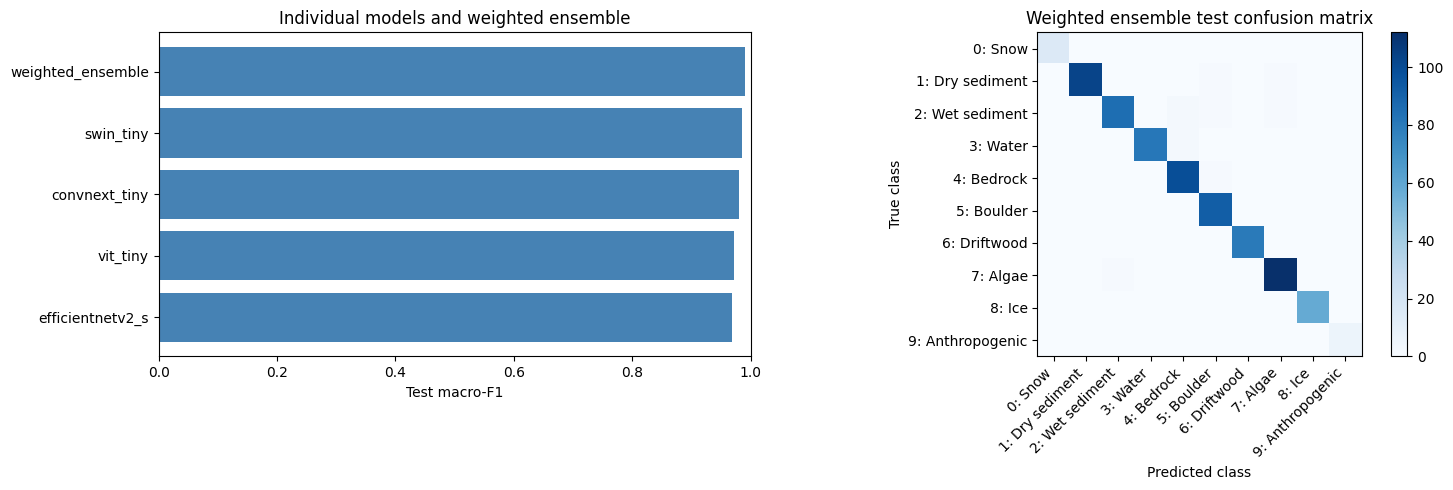

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_comparison = comparison_df.sort_values("macro_f1")
axes[0].barh(plot_comparison["model"], plot_comparison["macro_f1"], color="steelblue")
axes[0].set_xlabel("Test macro-F1")
axes[0].set_xlim(0, 1)
axes[0].set_title("Individual models and weighted ensemble")

image = axes[1].imshow(ensemble_confusion.to_numpy(), cmap="Blues")
axes[1].set_xticks(range(len(ensemble_confusion.columns)))
axes[1].set_yticks(range(len(ensemble_confusion.index)))
axes[1].set_xticklabels(ensemble_confusion.columns, rotation=45, ha="right")
axes[1].set_yticklabels(ensemble_confusion.index)
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_title("Weighted ensemble test confusion matrix")
fig.colorbar(image, ax=axes[1])

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_ensemble_comparison.png", dpi=150)
plt.show()